# **Entrega M2 — Dados, Pipeline, Split e Auditoria**
### Projeto Final de Visão Computacional • Tema 3: Lesões de pele (ISIC 2018 / HAM10000)

**Aluna:** Alice De Muylder Oliveira

**Pergunta de controle:** *se o treinamento começasse hoje, seria possível reconstruir exatamente os dados e confiar na avaliação?*

Este notebook é o **pipeline reprodutível** da entrega M2. Rodando **Kernel → Restart & Run All** ele:

1. indexa as imagens e máscaras e constrói o **manifesto** (uma linha por imagem: `sample_id`, caminho, rótulo, `group_id`, split, hash...);
2. **audita** os dados: integridade, formatos, duplicatas exatas (hash) e quase-duplicatas (dHash), rótulos, máscaras, distribuições, metadados e atalhos visuais;
3. faz o **split treino/validação/teste por grupo** (sem vazamento) com seed fixa e testes automáticos;
4. define a **política de transformações** (determinísticas para todos, aleatórias só no treino) e testa o pipeline;
5. **exporta** `manifest.csv`, `train.csv`, `validation.csv`, `test.csv`, figuras, `requirements.txt` e `README_M2.md` em `outputs_M2/`.

> O conjunto de **teste não é usado para nenhuma decisão** neste notebook: as análises que treinam algo (ex.: checagem de atalhos) usam só treino e validação.

## 0. Configuração e reprodutibilidade
Tudo que influencia o resultado (seed, caminhos, proporções, limiar de quase-duplicata) fica nesta célula.

In [20]:
import os, sys, json, hashlib, platform, random, re, subprocess, datetime as dt
import warnings
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image, ImageEnhance
import sklearn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score

# ------------------------- parâmetros do pipeline -------------------------
SEED = 42                                   # seed principal (split, amostragens, modelo de checagem)
random.seed(SEED); np.random.seed(SEED)

DATA_DIR      = Path("data")
METADATA_PATH = DATA_DIR / "metadata" / "HAM10000_metadata.csv"
IMAGES_DIR    = DATA_DIR / "images"         # Task 3 — classificação (busca recursiva)
MASKS_DIR     = DATA_DIR / "masks"          # Task 1 — segmentação   (busca recursiva)

OUT_DIR = Path("outputs_M2"); FIG_DIR = OUT_DIR / "figuras"
OUT_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)

SPLIT_FRACTIONS    = {"train": 0.70, "validation": 0.15, "test": 0.15}
NEAR_DUP_MAX_DIST  = 10       # 1º filtro (barato): distância de Hamming máxima, de 64 bits do dHash
NEAR_DUP_MAX_MAE   = 4.0      # 2º filtro (confirmação): erro absoluto médio (0-255) entre miniaturas coloridas 32x24
IMG_SIZE           = 224      # entrada planejada da rede
N_WORKERS          = min(8, os.cpu_count() or 1)

DATASET_NAME = "ISIC 2018 Challenge — Task 3 (HAM10000) + Task 1 (máscaras)"
DATASET_URL  = "https://challenge.isic-archive.com/data/#2018"
LICENSE      = "CC BY-NC 4.0"
DX_LABELS = {
    "nv": "Nevo melanocítico", "mel": "Melanoma", "bkl": "Ceratose benigna",
    "bcc": "Carcinoma basocelular", "akiec": "Ceratose actínica / Bowen",
    "vasc": "Lesão vascular", "df": "Dermatofibroma",
}

pd.set_option("display.max_columns", None); pd.set_option("display.width", 180)
plt.rcParams["figure.dpi"] = 100

RUN_STARTED = dt.datetime.now()
ENV = {
    "python": platform.python_version(), "sistema": f"{platform.system()} {platform.release()}",
    "numpy": np.__version__, "pandas": pd.__version__, "pillow": PIL.__version__,
    "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
}
print("Execução iniciada em:", RUN_STARTED.strftime("%d/%m/%Y %H:%M:%S"))
for k, v in ENV.items(): print(f"  {k:13s} {v}")
S = {}   # resumo da auditoria: alimenta o README e a planilha no final

Execução iniciada em: 16/10/2026 19:42:42
  python        3.12.7
  sistema       Windows 11
  numpy         2.5.2
  pandas        2.3.3
  pillow        12.3.0
  scikit-learn  1.9.0
  matplotlib    3.11.1


## 1. Indexação dos arquivos
A busca é **recursiva** (`rglob`): não importa quantas subpastas o ZIP do ISIC criou por baixo de `data/images` e `data/masks`.

In [21]:
def build_file_index(root_dir, extensions):
    """{nome_sem_extensão: caminho} buscando recursivamente. Ordem determinística (sorted)."""
    index = {}
    if not root_dir.exists():
        return index
    for ext in extensions:
        for p in sorted(root_dir.rglob(f"*{ext}")):
            index[p.stem] = p
    return index

IMAGE_INDEX = build_file_index(IMAGES_DIR, [".jpg", ".jpeg", ".png"])
MASK_INDEX  = build_file_index(MASKS_DIR,  [".png"])
print(f"Imagens encontradas (recursivo): {len(IMAGE_INDEX)}")
print(f"Máscaras encontradas (recursivo): {len(MASK_INDEX)}")
assert METADATA_PATH.exists(), f"Metadados não encontrados em {METADATA_PATH}"
assert len(IMAGE_INDEX) > 0, f"Nenhuma imagem em {IMAGES_DIR}"

Imagens encontradas (recursivo): 10015
Máscaras encontradas (recursivo): 2594


## 2. Metadados e auditoria de rótulos
Checamos colunas obrigatórias, classes fora das 7 esperadas, rótulos ausentes e — o ponto mais importante para o split —
**lesões (`lesion_id`) com rótulos diferentes** entre suas imagens.

In [22]:
meta = pd.read_csv(METADATA_PATH)
required = {"lesion_id", "image_id", "dx", "dx_type", "age", "sex", "localization"}
assert required <= set(meta.columns), f"Colunas faltando no metadata: {required - set(meta.columns)}"
meta["image_id"] = meta["image_id"].astype(str)
print(f"Registros no metadata: {len(meta)}  |  lesões únicas: {meta['lesion_id'].nunique()}")

invalid_dx   = meta[~meta["dx"].isin(DX_LABELS.keys())]
no_lesion_id = meta[meta["lesion_id"].isna()]
dup_image_id = meta[meta["image_id"].duplicated(keep=False)]
n_dx_per_lesion = meta.dropna(subset=["dx"]).groupby("lesion_id")["dx"].nunique()
CONFLICT_LESIONS = set(n_dx_per_lesion[n_dx_per_lesion > 1].index)
orphans = sorted(set(IMAGE_INDEX) - set(meta["image_id"]) - {m.replace("_segmentation", "") for m in MASK_INDEX})

S["labels"] = {
    "n_metadata": int(len(meta)), "n_lesions": int(meta["lesion_id"].nunique()),
    "dx_invalido_ou_ausente": int(len(invalid_dx)), "sem_lesion_id": int(len(no_lesion_id)),
    "image_id_duplicado_no_metadata": int(len(dup_image_id)),
    "lesoes_com_rotulos_conflitantes": int(len(CONFLICT_LESIONS)),
    "imagens_em_disco_sem_metadata": int(len(orphans)),
}
for k, v in S["labels"].items(): print(f"  {k}: {v}")
display(meta.isnull().sum().rename("nulos").to_frame().T)

Registros no metadata: 10015  |  lesões únicas: 7470
  n_metadata: 10015
  n_lesions: 7470
  dx_invalido_ou_ausente: 0
  sem_lesion_id: 0
  image_id_duplicado_no_metadata: 0
  lesoes_com_rotulos_conflitantes: 0
  imagens_em_disco_sem_metadata: 0


,lesion_id,image_id,dx,dx_type,age,sex,localization
nulos,0,0,0,0,57,0,0


## 3. Varredura de todas as imagens (integridade, formato, hash, dHash, brilho, nitidez)
Cada arquivo é aberto **uma vez**: `verify()` + `load()` (detecta arquivo truncado), dimensões/canais, **SHA-256** do arquivo
(duplicatas exatas), **dHash de 64 bits** (quase-duplicatas), brilho e nitidez (variância do Laplaciano em miniatura).

In [23]:
def scan_image(path):
    rec = {"file_hash": "", "width": np.nan, "height": np.nan, "channels": np.nan, "mode": "",
           "file_size": int(path.stat().st_size), "integrity_status": "OK", "issue_type": "",
           "dhash": "", "brightness": np.nan, "sharpness": np.nan, "thumb": None}
    try:
        rec["file_hash"] = hashlib.sha256(path.read_bytes()).hexdigest()
        with Image.open(path) as im:
            im.verify()                        # estrutura do arquivo
        with Image.open(path) as im:
            im.load()                          # decodifica de fato (pega JPEG truncado)
            rec["width"], rec["height"] = im.size
            rec["mode"], rec["channels"] = im.mode, len(im.getbands())
            g = im.convert("L")
            a = np.asarray(g.resize((9, 8), Image.LANCZOS), dtype=np.int16)
            bits = (a[:, 1:] > a[:, :-1]).flatten()                     # 64 bits
            rec["dhash"] = np.packbits(bits).tobytes().hex()
            t = np.asarray(g.resize((150, 112)), dtype=np.float32)
            rec["brightness"] = float(t.mean())
            lap = -4 * t[1:-1, 1:-1] + t[:-2, 1:-1] + t[2:, 1:-1] + t[1:-1, :-2] + t[1:-1, 2:]
            rec["sharpness"] = float(lap.var())
            rec["thumb"] = np.asarray(im.convert("RGB").resize((32, 24), Image.BILINEAR), dtype=np.uint8)   # confirmação de quase-duplicata
    except Exception as e:                      # arquivo ilegível/corrompido
        rec["integrity_status"] = "CORROMPIDO"
        rec["issue_type"] = f"{type(e).__name__}: {str(e)[:80]}"
    return rec

ids_on_disk = [i for i in sorted(meta["image_id"].unique()) if i in IMAGE_INDEX]
print(f"Varrendo {len(ids_on_disk)} imagens com {N_WORKERS} threads...")
scan_rows = []
CHUNK = 1000
with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
    for s in range(0, len(ids_on_disk), CHUNK):
        part = ids_on_disk[s:s + CHUNK]
        res = list(ex.map(lambda i: scan_image(IMAGE_INDEX[i]), part))     # map preserva a ordem
        scan_rows += [dict(image_id=i, **r) for i, r in zip(part, res)]
        print(f"  {min(s + CHUNK, len(ids_on_disk))}/{len(ids_on_disk)}", end="\r")
scan_df = pd.DataFrame(scan_rows)
THUMBS = {r["image_id"]: r["thumb"] for r in scan_rows if r["thumb"] is not None}      # miniaturas p/ confirmar quase-duplicatas
scan_df = scan_df.drop(columns=["thumb"])
print("\nVarredura concluída.  Status de integridade:", scan_df["integrity_status"].value_counts().to_dict())

Varrendo 10015 imagens com 8 threads...
  10015/10015
Varredura concluída.  Status de integridade: {'OK': 10015}


## 4. Manifesto
Uma linha por imagem do metadata. Regras de **inclusão/exclusão** (registradas em `include?` e `exclusion_reason`):

| Situação | Decisão |
|---|---|
| arquivo ausente ou corrompido | **excluir** |
| rótulo ausente/inválido, ou `lesion_id` com rótulos conflitantes | **excluir** (rótulo não confiável) |
| duplicata **exata** (mesmo SHA-256) | **manter a primeira**, excluir as cópias (evita contar duas vezes e vazar entre splits) |
| formato diferente do padrão (tamanho/canais) | **manter**; o pré-processamento converte para RGB e redimensiona |
| quase-duplicata (dHash) | **manter**, mas forçar o **mesmo split** (ver seção 5) |

In [24]:
m = meta.sort_values("image_id").reset_index(drop=True).copy()
m = m.merge(scan_df, on="image_id", how="left")

m["sample_id"] = m["image_id"]
m["file_path"] = m["image_id"].map(lambda i: IMAGE_INDEX[i].as_posix() if i in IMAGE_INDEX else "")
m["label"]     = m["dx"]
m["group_id"]  = m["lesion_id"].fillna(m["image_id"])          # sem lesion_id => a própria imagem é o grupo
m["source"]    = "ISIC 2018 Task 3 / HAM10000"
m["license"]   = LICENSE
m["annotation_path"] = m["image_id"].map(lambda i: MASK_INDEX[i + "_segmentation"].as_posix() if (i + "_segmentation") in MASK_INDEX else "")
m["object_count"] = ""

# ---- integridade ----
m.loc[m["file_path"] == "", ["integrity_status", "issue_type"]] = ["AUSENTE", "arquivo não encontrado em data/images"]

# ---- formato (informativo; não exclui) ----
valid = m["integrity_status"] == "OK"
modal_size = m.loc[valid].groupby(["width", "height"]).size().idxmax()
modal_mode = m.loc[valid, "mode"].mode().iloc[0]
odd_fmt = valid & ((m["width"] != modal_size[0]) | (m["height"] != modal_size[1]) | (m["mode"] != modal_mode))
m.loc[odd_fmt, "issue_type"] = ("formato fora do padrão (" + m["width"].astype("Int64").astype(str) + "x" +
                                m["height"].astype("Int64").astype(str) + " " + m["mode"].astype(str) +
                                f"; padrão {int(modal_size[0])}x{int(modal_size[1])} {modal_mode})")

# ---- inclusão / exclusão ----
m["include?"] = "Sim"; m["exclusion_reason"] = ""; m["notes"] = ""
def exclude(mask, reason):
    mask = mask & (m["include?"] == "Sim")
    m.loc[mask, "exclusion_reason"] = reason
    m.loc[mask, "include?"] = "Não"
    return int(mask.sum())

n_ex = {}
n_ex["ausente"]    = exclude(m["integrity_status"] == "AUSENTE",    "arquivo ausente")
n_ex["corrompido"] = exclude(m["integrity_status"] == "CORROMPIDO", "arquivo corrompido ou ilegível")
n_ex["rotulo_invalido"]    = exclude(~m["label"].isin(DX_LABELS.keys()), "rótulo ausente ou inválido")
n_ex["rotulo_conflitante"] = exclude(m["group_id"].isin(CONFLICT_LESIONS), "rótulos conflitantes dentro do mesmo lesion_id")

# duplicatas EXATAS (hash idêntico) entre arquivos legíveis
hash_groups = m[m["file_hash"].notna() & (m["file_hash"] != "") & (m["integrity_status"] == "OK")].groupby("file_hash")["image_id"].apply(list)
exact_groups = [sorted(g) for g in hash_groups if len(g) > 1]
n_exact_extra = 0
for g in exact_groups:
    keep, extras = g[0], g[1:]
    m.loc[m["image_id"] == keep, "notes"] = "tem cópia(s) exata(s): " + ", ".join(extras)
    n_exact_extra += exclude(m["image_id"].isin(extras), f"duplicata exata de {keep}")
n_ex["duplicata_exata"] = n_exact_extra

S["integridade"] = {"ok": int((m["integrity_status"] == "OK").sum()), "ausentes": int((m["integrity_status"] == "AUSENTE").sum()),
                    "corrompidos": int((m["integrity_status"] == "CORROMPIDO").sum())}
S["formato"] = {"padrao": f"{int(modal_size[0])}x{int(modal_size[1])} {modal_mode}", "fora_do_padrao": int(odd_fmt.sum()),
                "tamanhos_unicos": int(m.loc[valid].groupby(["width", "height"]).ngroups), "modos": m.loc[valid, "mode"].value_counts().to_dict()}
S["duplicatas_exatas"] = {"grupos": len(exact_groups), "copias_excluidas": n_exact_extra}
S["exclusoes"] = n_ex
print("Integridade:", S["integridade"]); print("Formato:", S["formato"])
print("Duplicatas exatas:", S["duplicatas_exatas"]); print("Exclusões:", n_ex)
print(f"\nIncluídas no pipeline: {(m['include?'] == 'Sim').sum()} de {len(m)}")

Integridade: {'ok': 10015, 'ausentes': 0, 'corrompidos': 0}
Formato: {'padrao': '600x450 RGB', 'fora_do_padrao': 0, 'tamanhos_unicos': 1, 'modos': {'RGB': 10015}}
Duplicatas exatas: {'grupos': 2, 'copias_excluidas': 2}
Exclusões: {'ausente': 0, 'corrompido': 0, 'rotulo_invalido': 0, 'rotulo_conflitante': 0, 'duplicata_exata': 2}

Incluídas no pipeline: 10013 de 10015


## 5. Quase-duplicatas e grupos de split
Duas fotos quase idênticas (mesma lesão fotografada de novo, ou lesões diferentes com a mesma imagem por erro) **não podem cair em splits diferentes**.
Procuramos candidatos com dHash a ≤ `NEAR_DUP_MAX_DIST` bits e **confirmamos** comparando miniaturas coloridas (erro absoluto médio ≤ `NEAR_DUP_MAX_MAE`) — o dHash sozinho gera falsos positivos em
imagens suaves como as dermatoscópicas. Os pares confirmados **unem** os `lesion_id`s envolvidos em um mesmo grupo de split (`capture_group`).

In [25]:
class DSU:
    """Union-Find determinístico (a raiz é sempre o menor elemento)."""
    def __init__(self): self.p = {}
    def find(self, x):
        self.p.setdefault(x, x)
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]; x = self.p[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb: self.p[max(ra, rb)] = min(ra, rb)

_LUT = np.array([bin(x).count("1") for x in range(256)], dtype=np.uint8)
def hamming_pairs(hashes, max_dist, chunk=256):
    """Todos os pares (i<j) com distância de Hamming <= max_dist. hashes: array uint64."""
    n, out = len(hashes), []
    for s in range(0, n, chunk):
        x = np.bitwise_xor(hashes[s:s + chunk, None], hashes[None, :])
        d = _LUT[x.view(np.uint8).reshape(x.shape[0], x.shape[1], 8)].sum(axis=2)
        ii, jj = np.where(d <= max_dist)
        out += [(int(i + s), int(j), int(d[i, j])) for i, j in zip(ii, jj) if i + s < j]
    return out

cand = m[(m["include?"] == "Sim") & (m["dhash"] != "")].reset_index()          # 'index' = posição em m
hashes = np.array([int(h, 16) for h in cand["dhash"]], dtype=np.uint64)
cand_pairs = hamming_pairs(hashes, NEAR_DUP_MAX_DIST)
def _mae(i, j):
    return float(np.abs(THUMBS[cand.loc[i, "image_id"]].astype(np.int16) - THUMBS[cand.loc[j, "image_id"]].astype(np.int16)).mean())
pairs = [(i, j, d, _mae(i, j)) for i, j, d in cand_pairs]
n_candidates = len(pairs)
pairs = [t for t in pairs if t[3] <= NEAR_DUP_MAX_MAE]
print(f"Candidatos por dHash (≤ {NEAR_DUP_MAX_DIST} bits): {n_candidates}  |  confirmados por miniatura (MAE ≤ {NEAR_DUP_MAX_MAE}): {len(pairs)}")

near_pairs = pd.DataFrame([{
    "a": cand.loc[i, "image_id"], "b": cand.loc[j, "image_id"], "dist": d, "mae": round(mae, 2),
    "lesion_a": cand.loc[i, "group_id"], "lesion_b": cand.loc[j, "group_id"],
    "label_a": cand.loc[i, "label"], "label_b": cand.loc[j, "label"]} for i, j, d, mae in pairs],
    columns=["a", "b", "dist", "mae", "lesion_a", "lesion_b", "label_a", "label_b"])
if len(near_pairs):
    near_pairs["same_lesion"] = near_pairs["lesion_a"] == near_pairs["lesion_b"]
    near_pairs["label_disagree"] = near_pairs["label_a"] != near_pairs["label_b"]
else:
    near_pairs["same_lesion"] = pd.Series(dtype=bool); near_pairs["label_disagree"] = pd.Series(dtype=bool)

# clusters de imagens (duplicate_group) e grupos de split (capture_group)
img_dsu, grp_dsu = DSU(), DSU()
for r in near_pairs.itertuples():
    img_dsu.union(r.a, r.b); grp_dsu.union(r.lesion_a, r.lesion_b)
inc_ids = m.loc[m["include?"] == "Sim", "image_id"].tolist()
roots = {i: img_dsu.find(i) for i in inc_ids if i in img_dsu.p}
sizes = pd.Series(list(roots.values())).value_counts()
cluster_names = {r: f"NEAR_{k:04d}" for k, r in enumerate(sorted(sizes[sizes > 1].index), start=1)}
m["duplicate_group"] = m["image_id"].map(lambda i: cluster_names.get(roots.get(i), ""))

inc_groups = sorted(set(m.loc[m["include?"] == "Sim", "group_id"]))
grp_root = {g: grp_dsu.find(g) for g in inc_groups}
sg_names = {r: f"SG{k:05d}" for k, r in enumerate(sorted(set(grp_root.values())), start=1)}
m["capture_group"] = m["group_id"].map(lambda g: sg_names.get(grp_root.get(g), ""))

merged = pd.Series(grp_root).groupby(pd.Series(grp_root)).size()
S["quase_duplicatas"] = {
    "limiar_bits": NEAR_DUP_MAX_DIST, "limiar_mae": NEAR_DUP_MAX_MAE, "candidatos_dhash": int(n_candidates), "pares": int(len(near_pairs)),
    "pares_mesma_lesao": int(near_pairs["same_lesion"].sum()), "pares_lesoes_diferentes": int((~near_pairs["same_lesion"]).sum()),
    "pares_rotulos_diferentes": int(near_pairs["label_disagree"].sum()),
    "clusters": len(cluster_names), "imagens_em_clusters": int((m["duplicate_group"] != "").sum()),
    "grupos_de_split_que_fundem_lesoes": int((merged > 1).sum()),
}
for k, v in S["quase_duplicatas"].items(): print(f"  {k}: {v}")

Candidatos por dHash (≤ 10 bits): 440601  |  confirmados por miniatura (MAE ≤ 4.0): 28
  limiar_bits: 10
  limiar_mae: 4.0
  candidatos_dhash: 440601
  pares: 28
  pares_mesma_lesao: 28
  pares_lesoes_diferentes: 0
  pares_rotulos_diferentes: 0
  clusters: 26
  imagens_em_clusters: 53
  grupos_de_split_que_fundem_lesoes: 0


## 6. Split treino / validação / teste (por grupo, com seed)
**Estratégia:** `GroupShuffleSplit` (scikit-learn) sobre o `capture_group` — que contém o `lesion_id` **e** funde lesões ligadas por quase-duplicatas.
Todas as imagens de um mesmo grupo ficam no mesmo conjunto. A proporção de classes **não** é controlada pela divisão (não é estratificada);
ela é **verificada depois** (seção 7) e eventuais desvios ficam documentados.

> Observação: `GroupShuffleSplit` sorteia **grupos**, então o percentual de *imagens* fica próximo — e não exatamente igual — a 70/15/15.

In [26]:
def make_split(df, group_col="capture_group", seed=SEED, fractions=SPLIT_FRACTIONS):
    """Devolve um pd.Series (index = índice de df) com 'train'/'validation'/'test'. Determinístico dada a seed."""
    gss1 = GroupShuffleSplit(n_splits=1, train_size=fractions["train"], random_state=seed)
    tr, tmp = next(gss1.split(df, groups=df[group_col]))
    tmp_df = df.iloc[tmp]
    rel_val = fractions["validation"] / (fractions["validation"] + fractions["test"])
    gss2 = GroupShuffleSplit(n_splits=1, train_size=rel_val, random_state=seed)
    va, te = next(gss2.split(tmp_df, groups=tmp_df[group_col]))
    out = pd.Series("", index=df.index, dtype=object)
    out.iloc[tr] = "train"; out.loc[tmp_df.index[va]] = "validation"; out.loc[tmp_df.index[te]] = "test"
    return out

inc = m[m["include?"] == "Sim"]
m["split"] = ""
m.loc[inc.index, "split"] = make_split(inc)

def split_fingerprint(df):
    """Hash do conteúdo do split (ids por conjunto) — prova de reconstrução exata."""
    h = hashlib.sha256()
    for sp in ["train", "validation", "test"]:
        h.update(sp.encode()); h.update(",".join(sorted(df.loc[df["split"] == sp, "image_id"])).encode())
    return h.hexdigest()

inc = m[m["include?"] == "Sim"]
SPLIT_FP = split_fingerprint(m)
n = len(inc)
split_tbl = pd.DataFrame({
    "planejado_%": pd.Series(SPLIT_FRACTIONS) * 100,
    "imagens": inc["split"].value_counts().reindex(list(SPLIT_FRACTIONS)),
    "lesões": inc.groupby("split")["group_id"].nunique().reindex(list(SPLIT_FRACTIONS)),
})
split_tbl["observado_%"] = (split_tbl["imagens"] / n * 100).round(1)
display(split_tbl)
print("Fingerprint do split (sha256):", SPLIT_FP)

,planejado_%,imagens,lesões,observado_%
train,70.0,7002,5229,69.9
validation,15.0,1518,1120,15.2
test,15.0,1493,1121,14.9


Fingerprint do split (sha256): 11e321850b22dbb7eaf8058e6e05ddd0431724704e37b8aab045be8cb539a4a1


### 6.1 Testes de vazamento (todos devem dar **0**)

In [27]:
def n_cross(df, col):
    """Quantos valores de `col` aparecem em mais de um split (ignora vazio)."""
    d = df[df[col] != ""]
    return int((d.groupby(col)["split"].nunique() > 1).sum())

inc = m[m["include?"] == "Sim"]
leak = {
    "lesion_id (group_id) em mais de um split": n_cross(inc, "group_id"),
    "grupo de split (capture_group) em mais de um split": n_cross(inc, "capture_group"),
    "cluster de quase-duplicatas em mais de um split": n_cross(inc, "duplicate_group"),
    "arquivo idêntico (SHA-256) em mais de um split": n_cross(inc, "file_hash"),
    "imagens incluídas sem split": int((inc["split"] == "").sum()),
}
for k, v in leak.items(): print(f"{'OK ' if v == 0 else 'FALHA'}  {k}: {v}")
assert all(v == 0 for v in leak.values()), "Vazamento detectado — revisar o split!"
S["split"] = {
    "estrategia": "Por grupos (GroupShuffleSplit sobre capture_group = lesion_id fundido com quase-duplicatas)", "seed": SEED, "fingerprint": SPLIT_FP,
    "imagens": {k: int(v) for k, v in split_tbl["imagens"].items()}, "lesoes": {k: int(v) for k, v in split_tbl["lesões"].items()},
    "percentual": {k: float(v) for k, v in split_tbl["observado_%"].items()}, "vazamento": leak,
}

OK   lesion_id (group_id) em mais de um split: 0
OK   grupo de split (capture_group) em mais de um split: 0
OK   cluster de quase-duplicatas em mais de um split: 0
OK   arquivo idêntico (SHA-256) em mais de um split: 0
OK   imagens incluídas sem split: 0


## 7. Auditoria de distribuição — classes por split  *(Figura 1)*

imagens                 % do split                 
split   train validation test      train validation  test
label                                                    
nv       4718        990  995       67.4       65.2  66.6
mel       770        156  187       11.0       10.3  12.5
bkl       741        206  152       10.6       13.6  10.2
bcc       381         65   68        5.4        4.3   4.6
akiec     207         57   63        3.0        3.8   4.2
vasc       96         25   21        1.4        1.6   1.4
df         89         19    7        1.3        1.3   0.5

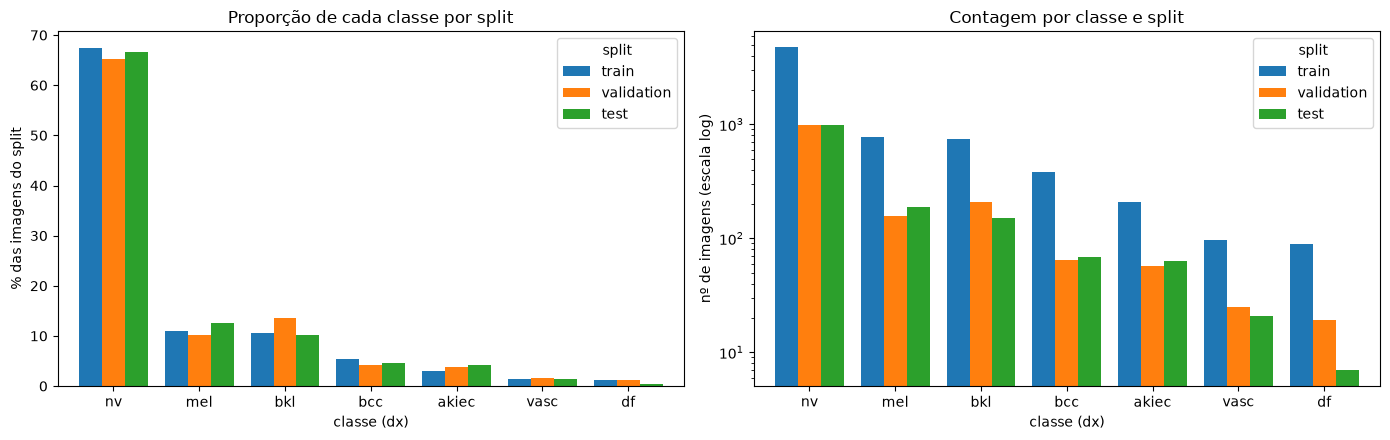

Razão classe majoritária/minoritária: 58.3x
Combinações classe×split com < 20 imagens (métrica instável): [('df', 'validation', 19), ('df', 'test', 7)]


In [28]:
order = inc["label"].value_counts().index.tolist()
ct = pd.crosstab(inc["label"], inc["split"]).reindex(order)[["train", "validation", "test"]]
pct = ct.div(ct.sum(axis=0), axis=1) * 100
display(pd.concat({"imagens": ct, "% do split": pct.round(1)}, axis=1))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
pct.plot(kind="bar", ax=ax[0], width=0.8); ax[0].set_ylabel("% das imagens do split"); ax[0].set_title("Proporção de cada classe por split")
ct.plot(kind="bar", ax=ax[1], width=0.8, logy=True); ax[1].set_ylabel("nº de imagens (escala log)"); ax[1].set_title("Contagem por classe e split")
for a in ax: a.set_xlabel("classe (dx)"); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_classes_por_split.png", dpi=130); plt.show()

small = [(c, sp, int(ct.loc[c, sp])) for c in ct.index for sp in ct.columns if ct.loc[c, sp] < 20]
razao = ct.sum(axis=1).max() / max(1, ct.sum(axis=1).min())
S["classes"] = {"contagem_total": {c: int(v) for c, v in ct.sum(axis=1).items()}, "razao_maj_min": round(float(razao), 1),
                "contagem_por_split": {c: {sp: int(ct.loc[c, sp]) for sp in ct.columns} for c in ct.index},
                "pct_por_split": {c: {sp: round(float(pct.loc[c, sp]), 1) for sp in pct.columns} for c in pct.index},
                "classe_split_com_menos_de_20": small}
print(f"Razão classe majoritária/minoritária: {razao:.1f}x")
print("Combinações classe×split com < 20 imagens (métrica instável):", small or "nenhuma")

## 8. Auditoria de formato, brilho e metadados  *(Figura 2)*

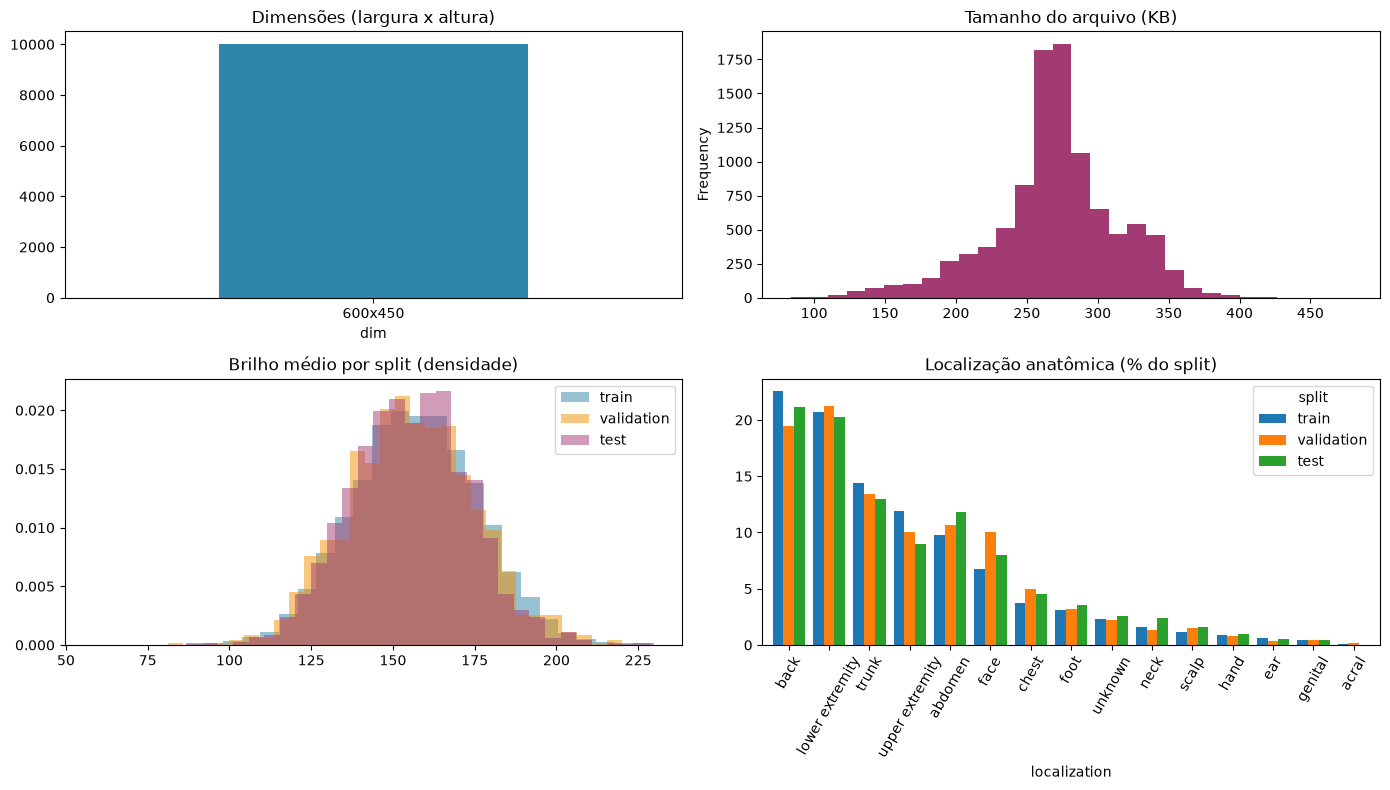

  idade_ausente: 57
  sexo_ausente_ou_unknown: 57
  localizacao_ausente_ou_unknown: 234
  dx_type: {'histo': 5338, 'follow_up': 3704, 'consensus': 902, 'confocal': 69}
  max_dif_pp_localizacao_entre_splits: 3.3
  max_dif_pp_sexo_entre_splits: 1.4
  idade_mediana_por_split: {'test': 50.0, 'train': 50.0, 'validation': 50.0}
  dimensões: {'aspecto_min': 1.333, 'aspecto_max': 1.333, 'tamanho_arquivo_kb_mediano': 270.4}


In [29]:
valid_inc = inc[inc["integrity_status"] == "OK"].copy()
valid_inc["dim"] = valid_inc["width"].astype(int).astype(str) + "x" + valid_inc["height"].astype(int).astype(str)
valid_inc["aspect"] = valid_inc["width"] / valid_inc["height"]

fig, ax = plt.subplots(2, 2, figsize=(14, 8))
valid_inc["dim"].value_counts().head(6).plot(kind="bar", ax=ax[0, 0], color="#2E86AB"); ax[0, 0].set_title("Dimensões (largura x altura)"); ax[0, 0].tick_params(axis="x", rotation=0)
(valid_inc["file_size"] / 1024).plot(kind="hist", bins=30, ax=ax[0, 1], color="#A23B72"); ax[0, 1].set_title("Tamanho do arquivo (KB)")
for sp, c in zip(["train", "validation", "test"], ["#2E86AB", "#F18F01", "#A23B72"]):
    ax[1, 0].hist(valid_inc.loc[valid_inc["split"] == sp, "brightness"], bins=30, alpha=0.5, density=True, label=sp, color=c)
ax[1, 0].set_title("Brilho médio por split (densidade)"); ax[1, 0].legend()
loc_ct = pd.crosstab(valid_inc["localization"].fillna("(ausente)"), valid_inc["split"], normalize="columns") * 100
loc_ct = loc_ct.loc[valid_inc["localization"].fillna("(ausente)").value_counts().index][["train", "validation", "test"]]
loc_ct.plot(kind="bar", ax=ax[1, 1], width=0.8); ax[1, 1].set_title("Localização anatômica (% do split)"); ax[1, 1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_formato_e_metadados.png", dpi=130); plt.show()

sex_ct = pd.crosstab(valid_inc["sex"].fillna("(ausente)"), valid_inc["split"], normalize="columns") * 100
S["metadados"] = {
    "idade_ausente": int(valid_inc["age"].isna().sum()), "sexo_ausente_ou_unknown": int(valid_inc["sex"].isna().sum() + (valid_inc["sex"] == "unknown").sum()),
    "localizacao_ausente_ou_unknown": int(valid_inc["localization"].isna().sum() + (valid_inc["localization"] == "unknown").sum()),
    "dx_type": valid_inc["dx_type"].value_counts().to_dict(),
    "max_dif_pp_localizacao_entre_splits": round(float((loc_ct.max(axis=1) - loc_ct.min(axis=1)).max()), 1),
    "max_dif_pp_sexo_entre_splits": round(float((sex_ct.max(axis=1) - sex_ct.min(axis=1)).max()), 1),
    "idade_mediana_por_split": {k: float(v) for k, v in valid_inc.groupby("split")["age"].median().items()},
}
S["dimensoes"] = {"aspecto_min": round(float(valid_inc["aspect"].min()), 3), "aspecto_max": round(float(valid_inc["aspect"].max()), 3),
                  "tamanho_arquivo_kb_mediano": round(float(valid_inc["file_size"].median() / 1024), 1)}
for k, v in S["metadados"].items(): print(f"  {k}: {v}")
print("  dimensões:", S["dimensoes"])

## 9. Máscaras de segmentação (Task 1) — validade, alinhamento e tamanho do objeto
Cada máscara deve ser binária, não vazia e, se a imagem correspondente existir localmente, ter **o mesmo tamanho** dela.
Também medimos a **fração da imagem ocupada pela lesão** (tamanho do objeto) e a **sobreposição** entre o conjunto de segmentação e o de classificação.

In [30]:
def scan_mask(item):
    mid, path = item
    iid = mid.replace("_segmentation", "")
    rec = {"mask_id": iid, "mask_path": path.as_posix(), "image_path": IMAGE_INDEX[iid].as_posix() if iid in IMAGE_INDEX else "",
           "has_image": iid in IMAGE_INDEX, "width": np.nan, "height": np.nan, "area_fraction": np.nan, "mask_valid": True, "issue": ""}
    try:
        with Image.open(path) as im:
            a = np.asarray(im.convert("L"))
            rec["width"], rec["height"] = im.size
        vals = set(np.unique(a).tolist())
        rec["area_fraction"] = float((a > 0).mean())
        if not (vals <= {0, 255} or vals <= {0, 1}): rec["mask_valid"], rec["issue"] = False, "máscara não binária"
        elif rec["area_fraction"] == 0:               rec["mask_valid"], rec["issue"] = False, "máscara vazia"
        elif rec["area_fraction"] == 1:               rec["mask_valid"], rec["issue"] = False, "máscara cobre a imagem toda"
        if rec["has_image"] and rec["mask_valid"]:
            with Image.open(IMAGE_INDEX[iid]) as im2:
                if im2.size != (rec["width"], rec["height"]): rec["mask_valid"], rec["issue"] = False, "máscara e imagem com tamanhos diferentes"
    except Exception as e:
        rec["mask_valid"], rec["issue"] = False, f"ilegível: {type(e).__name__}"
    return rec

if MASK_INDEX:
    with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
        seg = pd.DataFrame(list(ex.map(scan_mask, sorted(MASK_INDEX.items()))))
else:
    seg = pd.DataFrame(columns=["mask_id", "mask_path", "image_path", "has_image", "width", "height", "area_fraction", "mask_valid", "issue"])

cls_ids = set(meta["image_id"]); seg_ids = set(seg["mask_id"])
S["mascaras"] = {
    "n_mascaras": int(len(seg)), "invalidas": int((~seg["mask_valid"]).sum()) if len(seg) else 0,
    "motivos": seg.loc[~seg["mask_valid"], "issue"].value_counts().to_dict() if len(seg) else {},
    "com_imagem_local": int(seg["has_image"].sum()) if len(seg) else 0,
    "area_lesao_mediana_pct": round(float(seg["area_fraction"].median() * 100), 1) if len(seg) else None,
    "area_lesao_p5_p95_pct": [round(float(seg["area_fraction"].quantile(q) * 100), 1) for q in (0.05, 0.95)] if len(seg) else None,
    "sobreposicao_segmentacao_x_classificacao": int(len(seg_ids & cls_ids)),
    "imagens_de_classificacao": int(len(cls_ids)),
}
for k, v in S["mascaras"].items(): print(f"  {k}: {v}")
if S["mascaras"]["sobreposicao_segmentacao_x_classificacao"] == 0:
    print("\n>>> ACHADO: nenhuma imagem tem máscara E rótulo de diagnóstico. Segmentação e classificação são conjuntos de imagens DISJUNTOS.")
if S["mascaras"]["n_mascaras"] and S["mascaras"]["com_imagem_local"] == 0:
    print(">>> As imagens de entrada do Task 1 não estão em data/images: para treinar segmentação é preciso baixá-las (ISIC2018_Task1-2_Training_Input).")

  n_mascaras: 2594
  invalidas: 0
  motivos: {}
  com_imagem_local: 0
  area_lesao_mediana_pct: 13.8
  area_lesao_p5_p95_pct: [1.5, 65.2]
  sobreposicao_segmentacao_x_classificacao: 0
  imagens_de_classificacao: 10015

>>> ACHADO: nenhuma imagem tem máscara E rótulo de diagnóstico. Segmentação e classificação são conjuntos de imagens DISJUNTOS.
>>> As imagens de entrada do Task 1 não estão em data/images: para treinar segmentação é preciso baixá-las (ISIC2018_Task1-2_Training_Input).


## 10. Duplicatas e casos difíceis — inspeção visual  *(Figuras 3 e 4)*

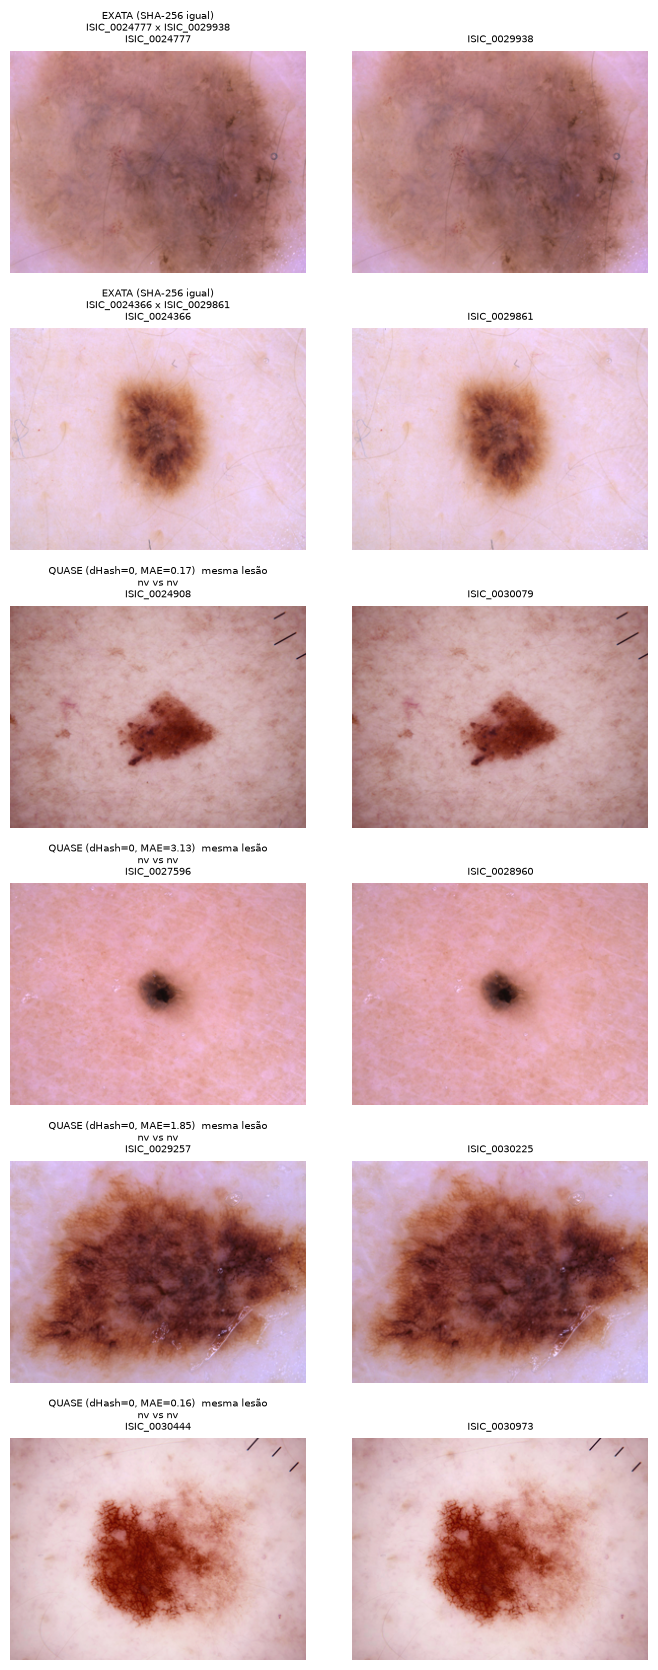

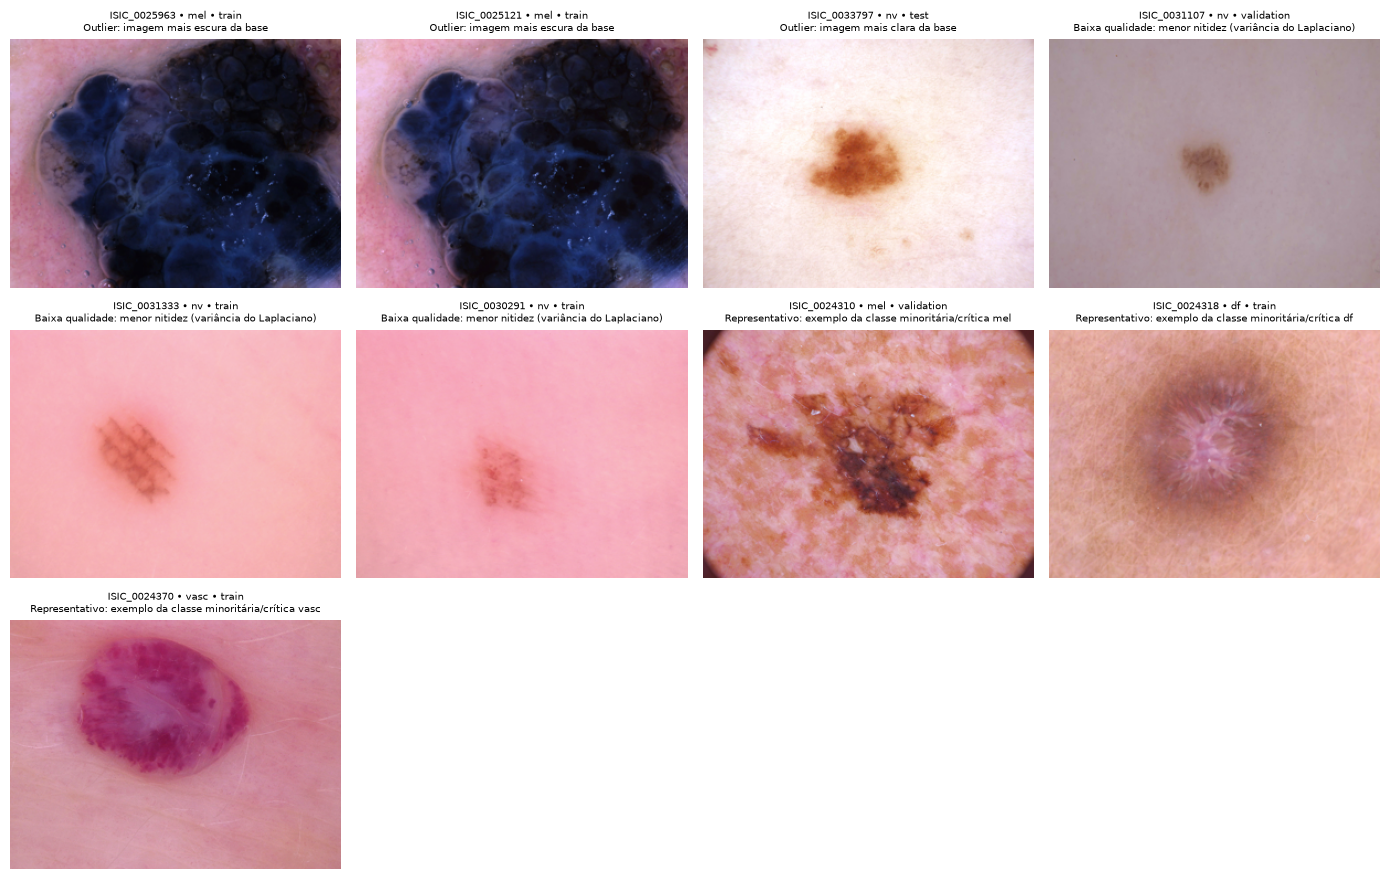

In [31]:
def thumb(image_id, size=(300, 225)):
    return Image.open(IMAGE_INDEX[image_id]).convert("RGB").resize(size)

# ---- Figura 3: duplicatas exatas (cópias excluídas) e quase-duplicatas ----
show = []
for g in exact_groups[:2]:
    show.append((g[0], g[1], f"EXATA (SHA-256 igual)\n{g[0]} x {g[1]}"))
if len(near_pairs):
    np_sorted = near_pairs.assign(prio=lambda d: (~d["label_disagree"]).astype(int) * 2 + d["same_lesion"].astype(int)).sort_values(["prio", "dist", "a"])
    for r in np_sorted.head(4).itertuples():
        show.append((r.a, r.b, f"QUASE (dHash={r.dist}, MAE={r.mae})  {'mesma lesão' if r.same_lesion else 'lesões DIFERENTES'}\n{r.label_a} vs {r.label_b}"))
fig3_ok = bool(show)
if show:
    fig, axes = plt.subplots(len(show), 2, figsize=(7, 2.8 * len(show)))
    axes = np.atleast_2d(axes)
    for k, (a_id, b_id, title) in enumerate(show):
        for j, iid in enumerate((a_id, b_id)):
            axes[k, j].imshow(thumb(iid)); axes[k, j].axis("off"); axes[k, j].set_title(iid if j else title + "\n" + iid, fontsize=7)
    plt.tight_layout()
else:
    fig, ax = plt.subplots(figsize=(6, 2)); ax.axis("off"); ax.text(0.5, 0.5, "Nenhuma duplicata exata ou quase-duplicata detectada", ha="center", va="center")
plt.savefig(FIG_DIR / "fig3_duplicatas.png", dpi=130); plt.show()

# ---- Figura 4: casos difíceis / representativos ----
cases, used = [], set()
def add_cases(df, case_type, reason, k):
    for r in df.head(k).itertuples():
        if r.image_id not in used:
            used.add(r.image_id); cases.append(dict(sample_id=r.image_id, label=r.label, split=r.split, case_type=case_type, reason=reason))
vi = inc[inc["integrity_status"] == "OK"]
add_cases(vi.sort_values(["brightness", "image_id"]),                   "Outlier",        "imagem mais escura da base", 2)
add_cases(vi.sort_values(["brightness", "image_id"], ascending=[False, True]), "Outlier", "imagem mais clara da base", 1)
add_cases(vi.sort_values(["sharpness", "image_id"]),                    "Baixa qualidade", "menor nitidez (variância do Laplaciano)", 3)
if len(near_pairs):
    dis = near_pairs[near_pairs["label_disagree"]].sort_values(["dist", "a"])
    add_cases(m[m["image_id"].isin(dis["a"])].sort_values("image_id"), "Ambíguo", "quase-duplicata com rótulo diferente", 2)
add_cases(m[m["group_id"].isin(CONFLICT_LESIONS)].sort_values("image_id"), "Possível erro", "lesion_id com rótulos conflitantes (excluída)", 2)
for cls in ["mel", "df", "vasc"]:
    add_cases(vi[vi["label"] == cls].sort_values("image_id"), "Representativo", f"exemplo da classe minoritária/crítica {cls}", 1)
cases = [c for c in cases if c["sample_id"] in IMAGE_INDEX][:12]
cases_df = pd.DataFrame(cases)

fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax in axes.ravel(): ax.axis("off")
for ax, c in zip(axes.ravel(), cases):
    ax.imshow(thumb(c["sample_id"])); ax.set_title(f"{c['sample_id']} • {c['label']} • {c['split'] or 'excl.'}\n{c['case_type']}: {c['reason']}", fontsize=7)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_casos_dificeis.png", dpi=130); plt.show()
S["inspecao_visual"] = cases

## 11. Atalhos visuais — o que *não* é a lesão prevê a classe?
Treinamos um modelo simples (Random Forest) usando **apenas** propriedades técnicas da imagem (largura, altura, tamanho do arquivo, brilho, nitidez) para prever a classe.
Se a acurácia balanceada ficar bem acima do acaso (1/nº de classes), há risco de a rede aprender o "estilo da foto" em vez da lesão.
Usa **somente treino → validação** (o teste não é tocado).

In [32]:
feat = ["width", "height", "file_size", "brightness", "sharpness"]
tr = valid_inc[valid_inc["split"] == "train"]; va = valid_inc[valid_inc["split"] == "validation"]
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced", random_state=SEED, n_jobs=-1)
rf.fit(tr[feat], tr["label"])
bacc = balanced_accuracy_score(va["label"], rf.predict(va[feat]))
chance = 1 / valid_inc["label"].nunique()
imp = pd.Series(rf.feature_importances_, index=feat).sort_values(ascending=False).round(3)
print(f"Acurácia balanceada (validação) só com propriedades técnicas: {bacc:.3f}  |  acaso: {chance:.3f}")
print("Importância das propriedades:", imp.to_dict())
S["atalhos"] = {"features": feat, "balanced_accuracy_val": round(float(bacc), 3), "acaso": round(float(chance), 3),
                "importancias": imp.to_dict(), "alerta": bool(bacc > chance + 0.10)}
print("ALERTA de atalho visual." if S["atalhos"]["alerta"] else "Sem sinal forte de atalho técnico (diferença para o acaso ≤ 0,10).")

Acurácia balanceada (validação) só com propriedades técnicas: 0.291  |  acaso: 0.143
Importância das propriedades: {'file_size': 0.356, 'sharpness': 0.337, 'brightness': 0.307, 'width': 0.0, 'height': 0.0}
ALERTA de atalho visual.


## 12. Pré-processamento e aumento de dados  *(Figura 5)*
**Regra:** operações **determinísticas** (RGB, redimensionar, normalizar) valem para *todos* os splits; aumentos **aleatórios** valem **só para o treino**.
Os aumentos escolhidos preservam o rótulo: dermatoscopia não tem "cima/baixo" nem lado, então *flips* e rotações de 90° (sem interpolação) são seguros;
brilho/contraste mudam pouco (±15%) para não apagar a cor, que é evidência diagnóstica; **não** há mudança de matiz.
A normalização usa **somente estatísticas do treino**. Implementação em PIL/NumPy puros (independente de framework); em M3 vira `torchvision`/`albumentations` com os mesmos parâmetros.

In [33]:
# ------------------------- parâmetros dos aumentos (APENAS TREINO) -------------------------
P_FLIP_H = P_FLIP_V = P_ROT90 = P_CROP = P_COLOR = 0.5
CROP_SCALE, BRIGHT_RANGE, CONTRAST_RANGE = (0.80, 1.00), (0.85, 1.15), (0.85, 1.15)

def sample_geometry(rng, size):
    """Sorteia parâmetros geométricos. Aplicados IGUALMENTE a imagem e máscara (ordem: recorte, flipH, flipV, rotação)."""
    w, h = size
    g = {"flipH": bool(rng.random() < P_FLIP_H), "flipV": bool(rng.random() < P_FLIP_V),
         "rot": (int(rng.integers(1, 4)) * 90 if rng.random() < P_ROT90 else 0), "crop": None}
    if rng.random() < P_CROP:
        s = rng.uniform(*CROP_SCALE); cw, ch = int(round(w * s)), int(round(h * s))
        x0, y0 = int(rng.integers(0, w - cw + 1)), int(rng.integers(0, h - ch + 1))
        g["crop"] = (x0, y0, x0 + cw, y0 + ch)
    return g

def apply_geometry(img, g):
    if g["crop"]: img = img.crop(g["crop"])
    if g["flipH"]: img = img.transpose(Image.FLIP_LEFT_RIGHT)
    if g["flipV"]: img = img.transpose(Image.FLIP_TOP_BOTTOM)
    if g["rot"]:   img = img.rotate(g["rot"], expand=True)       # múltiplos de 90°: transposição exata, sem interpolação
    return img

def augment_train(img, rng):
    g = sample_geometry(rng, img.size)
    img = apply_geometry(img, g)
    photo = None
    if rng.random() < P_COLOR:
        photo = (float(rng.uniform(*BRIGHT_RANGE)), float(rng.uniform(*CONTRAST_RANGE)))
        img = ImageEnhance.Contrast(ImageEnhance.Brightness(img).enhance(photo[0])).enhance(photo[1])
    return img, {"geometria": g, "foto": photo}

def load_rgb(path): return Image.open(path).convert("RGB")             # determinística

def to_tensor(img, mean, std):                                         # determinística: resize -> [0,1] -> normaliza -> CHW
    a = np.asarray(img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.float32) / 255.0
    return ((a - mean) / std).transpose(2, 0, 1).astype(np.float32)

def preprocess(path, mean, std, augment=False, rng=None):
    img = load_rgb(path)
    if augment: img, _ = augment_train(img, rng)
    return to_tensor(img, mean, std)

# ---- estatísticas de normalização: SOMENTE TREINO (amostra de até 600 imagens, seed fixa) ----
inc = m[m["include?"] == "Sim"]
train_ids = sorted(inc.loc[inc["split"] == "train", "image_id"])
stat_ids = sorted(np.random.default_rng(SEED).choice(train_ids, size=min(600, len(train_ids)), replace=False).tolist())
s1 = np.zeros(3); s2 = np.zeros(3)
for iid in stat_ids:
    a = np.asarray(load_rgb(IMAGE_INDEX[iid]).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.float32).reshape(-1, 3) / 255.0
    s1 += a.mean(0); s2 += (a ** 2).mean(0)
NORM_MEAN = (s1 / len(stat_ids)).astype(np.float32)
NORM_STD  = np.sqrt(s2 / len(stat_ids) - NORM_MEAN.astype(np.float64) ** 2).astype(np.float32)
with open(OUT_DIR / "normalization_stats.json", "w") as f:
    json.dump({"mean": NORM_MEAN.tolist(), "std": NORM_STD.tolist(), "n_imagens_treino_usadas": len(stat_ids), "img_size": IMG_SIZE, "seed": SEED}, f, indent=2)
print("mean:", NORM_MEAN.round(4), " std:", NORM_STD.round(4), f" (calculadas em {len(stat_ids)} imagens do TREINO)")

mean: [0.7661 0.5559 0.5804]  std: [0.1383 0.1515 0.1688]  (calculadas em 600 imagens do TREINO)


Lote de treino: (8, 3, 224, 224) float32
OK   shape_do_lote
OK   val_teste_deterministico
OK   mesma_seed_mesmo_aumento
OK   mascara_acompanha_geometria
OK   normalizacao_so_treino
OK   seed_reconstroi_split


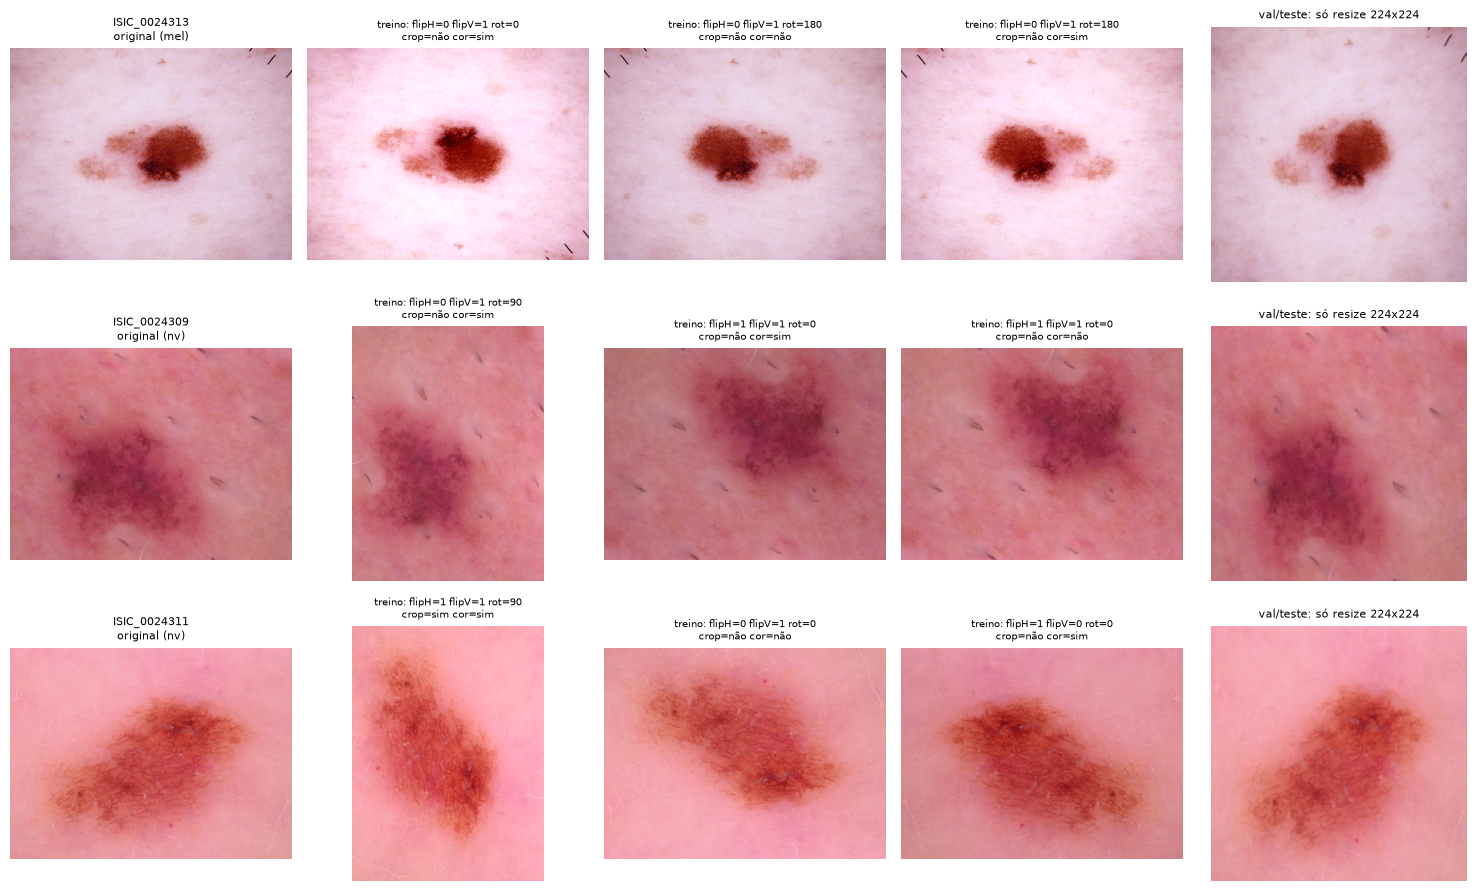

In [34]:
# ------------------------------- testes do pipeline -------------------------------
tests = {}

# 1) lote com shape esperado (treino com aumento; validação/teste determinísticos)
rng = np.random.default_rng(SEED)
batch_ids = train_ids[:8]
xb = np.stack([preprocess(IMAGE_INDEX[i], NORM_MEAN, NORM_STD, augment=True, rng=rng) for i in batch_ids])
tests["shape_do_lote"] = (xb.shape == (len(batch_ids), 3, IMG_SIZE, IMG_SIZE)) and xb.dtype == np.float32 and bool(np.isfinite(xb).all())
print("Lote de treino:", xb.shape, xb.dtype)

# 2) determinismo em validação/teste (sem aumento): duas passadas => idênticas
val_id = inc.loc[inc["split"] == "validation", "image_id"].iloc[0]
tests["val_teste_deterministico"] = bool(np.array_equal(preprocess(IMAGE_INDEX[val_id], NORM_MEAN, NORM_STD), preprocess(IMAGE_INDEX[val_id], NORM_MEAN, NORM_STD)))

# 3) mesma seed => mesmos aumentos
a1 = preprocess(IMAGE_INDEX[batch_ids[0]], NORM_MEAN, NORM_STD, True, np.random.default_rng(SEED))
a2 = preprocess(IMAGE_INDEX[batch_ids[0]], NORM_MEAN, NORM_STD, True, np.random.default_rng(SEED))
tests["mesma_seed_mesmo_aumento"] = bool(np.array_equal(a1, a2))

# 4) rótulos/máscaras acompanham a geometria: máscara pseudo-binária (pixels escuros) transformada junto com a imagem
#    deve coincidir EXATAMENTE com a máscara recalculada na imagem transformada
ok_align = True
for i in batch_ids[:5]:
    img = load_rgb(IMAGE_INDEX[i]); gray0 = np.asarray(img.convert("L")); thr = gray0.mean() - 10
    mask0 = Image.fromarray(((gray0 < thr) * 255).astype(np.uint8))
    g = sample_geometry(np.random.default_rng(SEED + 1), img.size)
    mask_t = np.asarray(apply_geometry(mask0, g)) > 0
    mask_re = np.asarray(apply_geometry(img, g).convert("L")) < thr
    ok_align &= bool(np.array_equal(mask_t, mask_re))
tests["mascara_acompanha_geometria"] = ok_align

# 5) normalização calculada só com o treino
tests["normalizacao_so_treino"] = set(stat_ids) <= set(train_ids) and not (set(stat_ids) & set(inc.loc[inc["split"] != "train", "image_id"]))

# 6) seed reconstrói o split
_inc_idx = m.index[m["include?"] == "Sim"]
_again = make_split(m.loc[_inc_idx])                                   # refaz o split do zero com a mesma seed
tests["seed_reconstroi_split"] = bool((_again.values == m.loc[_inc_idx, "split"].values).all()) and \
    split_fingerprint(m.assign(split=m["split"].where(~m.index.isin(_inc_idx), _again.reindex(m.index)))) == SPLIT_FP
for k, v in tests.items(): print(f"{'OK ' if v else 'FALHA'}  {k}")
assert all(tests.values()), "Algum teste do pipeline falhou"
S["testes_pipeline"] = {k: bool(v) for k, v in tests.items()}

# ---- Figura 5: original x aumentos (treino) x versão determinística (val/teste) ----
mel_train = inc[(inc["split"] == "train") & (inc["label"] == "mel")]["image_id"].head(1).tolist()
pick = list(dict.fromkeys(mel_train + train_ids[:2]))[:3]
fig, axes = plt.subplots(len(pick), 5, figsize=(15, 3 * len(pick)))
axes = np.atleast_2d(axes)
for r, iid in enumerate(pick):
    img = load_rgb(IMAGE_INDEX[iid]); rr = np.random.default_rng(SEED + r)
    axes[r, 0].imshow(img); axes[r, 0].set_title(f"{iid}\noriginal ({inc.set_index('image_id').loc[iid, 'label']})", fontsize=8)
    for c in range(1, 4):
        aug, info = augment_train(img, rr); g = info["geometria"]
        axes[r, c].imshow(aug)
        axes[r, c].set_title(f"treino: flipH={int(g['flipH'])} flipV={int(g['flipV'])} rot={g['rot']}\ncrop={'sim' if g['crop'] else 'não'} cor={'sim' if info['foto'] else 'não'}", fontsize=7)
    axes[r, 4].imshow(img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)); axes[r, 4].set_title(f"val/teste: só resize {IMG_SIZE}x{IMG_SIZE}", fontsize=8)
for ax in axes.ravel(): ax.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5_transformacoes.png", dpi=130); plt.show()

TRANSFORMS = [
    # operação, tipo, aplicar em, parâmetros, probabilidade, justificativa, rótulo válido?, risco, evidência
    ("Leitura/conversão RGB", "Determinística", "Todos", "Image.convert('RGB')", "1,0", "Padronizar canais (há imagens em outros modos)", "Sim", "Perda de informação se houver bandas extras", "Fig. 5 / teste shape_do_lote"),
    ("Redimensionamento", "Determinística", "Todos", f"resize {IMG_SIZE}x{IMG_SIZE}, bilinear (sem manter aspecto)", "1,0", "Compatibilizar a entrada da rede (imagens 600x450 → 224x224)", "Sim", "Distorção de aspecto (4:3 → 1:1)", "Fig. 5 (coluna val/teste)"),
    ("Normalização", "Determinística", "Todos", f"média/desvio por canal calculados SÓ no treino ({len(stat_ids)} imgs): mean={NORM_MEAN.round(3).tolist()} std={NORM_STD.round(3).tolist()}", "1,0", "Estabilizar escala numérica", "Sim", "Estatísticas calculadas fora do treino causariam vazamento (evitado)", "normalization_stats.json / teste normalizacao_so_treino"),
    ("Espelhamento", "Aleatória", "Treino", "flip horizontal e vertical, independentes", "0,5 cada", "Lesão dermatoscópica não tem lado/orientação preferencial", "Sim", "Nenhum relevante (localização anatômica não é usada como entrada)", "Fig. 5"),
    ("Rotação", "Aleatória", "Treino", "90°/180°/270° (sem interpolação)", "0,5", "Sem 'cima/baixo' em dermatoscopia; evita cantos pretos e reamostragem", "Sim", "Nenhum relevante", "Fig. 5 / teste mascara_acompanha_geometria"),
    ("Brilho/contraste", "Aleatória", "Treino", f"brilho {BRIGHT_RANGE}, contraste {CONTRAST_RANGE}; sem mudança de matiz", "0,5", "Robustez a iluminação/câmera sem destruir a cor (evidência diagnóstica)", "Sim", "Exagero poderia ocultar bordas/cores; faixa mantida estreita (±15%)", "Fig. 5"),
    ("Recorte/escala", "Aleatória", "Treino", f"recorte {CROP_SCALE[0]:.0%}–{CROP_SCALE[1]:.0%} da área em posição aleatória", "0,5", "Robustez a enquadramento", "Sim", "Pode cortar parte da lesão (lesões costumam ocupar o centro; recorte ≥ 80%)", "Fig. 5"),
]

## 13. Exportação: manifestos, requirements, README e verificação de reprodutibilidade

In [35]:
import importlib.metadata as imd
mcols = ["sample_id", "file_path", "label", "group_id", "source", "license", "width", "height", "channels", "annotation_path", "object_count",
         "integrity_status", "issue_type", "split", "file_hash", "duplicate_group", "capture_group", "notes", "include?", "exclusion_reason"]
extra = ["dx_type", "age", "sex", "localization", "mode", "file_size", "dhash", "brightness", "sharpness"]
manifest = m[mcols + extra].copy()
for c in ["width", "height", "channels"]: manifest[c] = manifest[c].astype("Int64")
manifest = manifest.sort_values("sample_id").reset_index(drop=True)

manifest.to_csv(OUT_DIR / "manifest.csv", index=False)
for sp in ["train", "validation", "test"]:
    manifest[manifest["split"] == sp].to_csv(OUT_DIR / f"{sp}.csv", index=False)
seg.to_csv(OUT_DIR / "manifest_segmentacao.csv", index=False)

# ---- confere o que foi gravado (releitura) ----
chk = {sp: pd.read_csv(OUT_DIR / f"{sp}.csv") for sp in ["train", "validation", "test"]}
assert sum(len(v) for v in chk.values()) == int((manifest["include?"] == "Sim").sum())
assert not (set(chk["train"]["sample_id"]) & set(chk["validation"]["sample_id"])) and not (set(chk["train"]["sample_id"]) & set(chk["test"]["sample_id"])) \
       and not (set(chk["validation"]["sample_id"]) & set(chk["test"]["sample_id"]))
MANIFEST_SHA = hashlib.sha256((OUT_DIR / "manifest.csv").read_bytes()).hexdigest()
print({sp: len(v) for sp, v in chk.items()}, "\nmanifest.csv sha256:", MANIFEST_SHA)

# ---- requirements.txt com as versões realmente usadas ----
pkgs = ["numpy", "pandas", "Pillow", "scikit-learn", "matplotlib"]
ver = {}
for p in pkgs:
    try: ver[p] = imd.version(p)
    except Exception: pass
(OUT_DIR / "requirements.txt").write_text(f"# Python {platform.python_version()}\n" + "\n".join(f"{p}=={v}" for p, v in ver.items()) + "\n", encoding="utf-8")

S["reprodutibilidade"] = {"seed": SEED, "manifest_sha256": MANIFEST_SHA, "split_fingerprint": SPLIT_FP, "ambiente": ENV, "pacotes": ver,
                          "split_reconstruido_com_a_seed": bool(tests["seed_reconstroi_split"])}
S["figuras"] = sorted(p.name for p in FIG_DIR.glob("*.png"))
with open(OUT_DIR / "audit_summary.json", "w", encoding="utf-8") as f:
    json.dump(S, f, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Figuras:", S["figuras"]); print("Arquivos em", OUT_DIR, ":", sorted(p.name for p in OUT_DIR.iterdir()))

{'train': 7002, 'validation': 1518, 'test': 1493} 
manifest.csv sha256: e07ef30dac9bae23ccf5235bd58e5fc8dd80efbc4e9e3a1979e5bcb33a60f47a
Figuras: ['fig1_classes_por_split.png', 'fig2_formato_e_metadados.png', 'fig3_duplicatas.png', 'fig4_casos_dificeis.png', 'fig5_transformacoes.png']
Arquivos em outputs_M2 : ['audit_summary.json', 'figuras', 'manifest.csv', 'manifest_segmentacao.csv', 'normalization_stats.json', 'requirements.txt', 'test.csv', 'train.csv', 'validation.csv']


In [36]:
# ------------------------------- README_M2.md (gerado com os números reais desta execução) -------------------------------
C = S["classes"]; Q = S["quase_duplicatas"]; MK = S["mascaras"]; AT = S["atalhos"]; SP = S["split"]
n_inc = int((manifest["include?"] == "Sim").sum())
cls_lines = "\n".join(f"| {c} | {DX_LABELS.get(c, c)} | {C['contagem_total'][c]} | " + " | ".join(str(C['contagem_por_split'][c][s]) for s in ["train", "validation", "test"]) + " |" for c in C["contagem_total"])
readme = f"""# Entrega M2 — Dados, pipeline, split e auditoria
Projeto Final de Visão Computacional — Lesões de pele (ISIC 2018 / HAM10000) — Alice De Muylder Oliveira

## Origem, licença e versão
- **Dados:** {DATASET_NAME} — {DATASET_URL}
- **Licença:** {LICENSE} (uso não comercial, com atribuição). Os dados **não** são redistribuídos neste repositório (`data/` está no `.gitignore`); baixe-os do ISIC.
- **Classificação:** {S['labels']['n_metadata']} imagens dermatoscópicas ({S['formato']['padrao']}) de {S['labels']['n_lesions']} lesões, 7 classes (`dx`).
- **Segmentação:** {MK['n_mascaras']} máscaras (Task 1).

## Como reproduzir
1. Baixar os dados do ISIC 2018 e organizar como `data/metadata/HAM10000_metadata.csv`, `data/images/...` (Task 3) e `data/masks/...` (Task 1). Subpastas internas não importam (busca recursiva).
2. `pip install -r outputs_M2/requirements.txt` (Python {platform.python_version()}).
3. Abrir `notebook_M2_pipeline.ipynb` nesta pasta e executar **Restart & Run All**. Tudo usa `SEED = {SEED}`.
4. Conferir que o `sha256` do `manifest.csv` e o fingerprint do split são os abaixo.

| | |
|---|---|
| seed | {SEED} |
| manifest.csv sha256 | `{MANIFEST_SHA}` |
| fingerprint do split | `{SPLIT_FP}` |

## Manifestos
`outputs_M2/manifest.csv` (todas as linhas, com `include?` e `exclusion_reason`), `train.csv`, `validation.csv`, `test.csv` ({n_inc} imagens incluídas) e `manifest_segmentacao.csv`.
Colunas principais: `sample_id`, `file_path`, `label`, `group_id` (= `lesion_id`), `split`, `file_hash`, `duplicate_group`, `capture_group`.

## Auditoria (resumo)
- **Integridade:** {S['integridade']['ok']} OK, {S['integridade']['ausentes']} ausentes, {S['integridade']['corrompidos']} corrompidos. **Formato:** {S['formato']['tamanhos_unicos']} tamanho(s) distinto(s); {S['formato']['fora_do_padrao']} fora do padrão ({S['formato']['padrao']}).
- **Duplicatas exatas (SHA-256):** {S['duplicatas_exatas']['grupos']} grupos; {S['duplicatas_exatas']['copias_excluidas']} cópias excluídas.
- **Quase-duplicatas (dHash ≤ {Q['limiar_bits']} bits + miniatura MAE ≤ {Q['limiar_mae']}):** {Q['candidatos_dhash']} candidatos, {Q['pares']} pares confirmados ({Q['pares_lesoes_diferentes']} entre lesões diferentes; {Q['pares_rotulos_diferentes']} com rótulos diferentes). Mantidas, mas forçadas ao mesmo split.
- **Rótulos:** {S['labels']['dx_invalido_ou_ausente']} inválidos/ausentes; {S['labels']['lesoes_com_rotulos_conflitantes']} lesões com rótulos conflitantes (excluídas).
- **Máscaras:** {MK['invalidas']} inválidas de {MK['n_mascaras']}; mediana da lesão = {MK['area_lesao_mediana_pct']}% da imagem. **Sobreposição segmentação × classificação: {MK['sobreposicao_segmentacao_x_classificacao']} imagens** — são conjuntos disjuntos; as imagens de entrada do Task 1 {'não estão' if MK['com_imagem_local'] == 0 else 'estão (' + str(MK['com_imagem_local']) + ')'} no disco local.
- **Atalhos visuais:** acurácia balanceada só com propriedades técnicas = {AT['balanced_accuracy_val']} (acaso = {AT['acaso']}) → {'ALERTA' if AT['alerta'] else 'sem sinal forte'}.
- Figuras em `outputs_M2/figuras/`.

## Split
Por grupos (`GroupShuffleSplit` sobre `capture_group` = `lesion_id` fundido com quase-duplicatas), seed {SEED}, alvo 70/15/15.
Observado: treino {SP['imagens']['train']} ({SP['percentual']['train']}%), validação {SP['imagens']['validation']} ({SP['percentual']['validation']}%), teste {SP['imagens']['test']} ({SP['percentual']['test']}%).
Testes de vazamento (lesão, grupo, cluster de quase-duplicatas, hash): **todos 0**. O teste fica bloqueado até a avaliação final.

| classe | descrição | total | treino | validação | teste |
|---|---|---|---|---|---|
{cls_lines}

## Transformações
Determinísticas em todos os splits: RGB → resize {IMG_SIZE}×{IMG_SIZE} → normalização com média/desvio do **treino** (`normalization_stats.json`).
Aleatórias **só no treino**: flips, rotações de 90°, recorte 80–100%, brilho/contraste ±15%. Todas preservam o rótulo.

## Limitações e riscos
- Desbalanceamento forte (razão maior/menor = {C['razao_maj_min']}x): usar perda ponderada e reportar recall por classe (especialmente melanoma).
- Combinações classe×split com menos de 20 imagens: {C['classe_split_com_menos_de_20'] or 'nenhuma'} → métricas instáveis nessas classes.
- Segmentação e classificação usam imagens diferentes: serão dois modelos avaliados separadamente.
- Datasets dermatoscópicos sub-representam tons de pele mais escuros; o dataset não traz esse metadado. Uso educacional — não substitui avaliação clínica.
- A estratégia **não** é estratificada por classe; a proporção de classes por split é apenas verificada.

## Pendências
- Revisão por outra pessoa (teste cruzado de reprodução) e inspeção das máscaras sobre as imagens do Task 1 (requer baixar as imagens de entrada).
"""
(OUT_DIR / "README_M2.md").write_text(readme, encoding="utf-8")
print("README_M2.md gerado.")

README_M2.md gerado.


## 14. Resumo da execução

In [37]:
print("=" * 78)
print(f"Imagens no metadata: {len(m)}  |  incluídas no pipeline: {int((m['include?'] == 'Sim').sum())}  |  excluídas: {int((m['include?'] == 'Não').sum())}")
print(f"Split (imagens): {S['split']['imagens']}  ->  {S['split']['percentual']} %")
print(f"Vazamento: {S['split']['vazamento']}")
print(f"Duplicatas exatas excluídas: {S['duplicatas_exatas']['copias_excluidas']}  |  pares quase-duplicatas: {S['quase_duplicatas']['pares']}")
print(f"Segmentação × classificação — imagens em comum: {S['mascaras']['sobreposicao_segmentacao_x_classificacao']}")
print(f"Testes do pipeline: {S['testes_pipeline']}")
print(f"manifest.csv sha256: {MANIFEST_SHA}")
print(f"Duração: {(dt.datetime.now() - RUN_STARTED).total_seconds():.0f} s")
print("=" * 78)

Imagens no metadata: 10015  |  incluídas no pipeline: 10013  |  excluídas: 2
Split (imagens): {'train': 7002, 'validation': 1518, 'test': 1493}  ->  {'train': 69.9, 'validation': 15.2, 'test': 14.9} %
Vazamento: {'lesion_id (group_id) em mais de um split': 0, 'grupo de split (capture_group) em mais de um split': 0, 'cluster de quase-duplicatas em mais de um split': 0, 'arquivo idêntico (SHA-256) em mais de um split': 0, 'imagens incluídas sem split': 0}
Duplicatas exatas excluídas: 2  |  pares quase-duplicatas: 28
Segmentação × classificação — imagens em comum: 0
Testes do pipeline: {'shape_do_lote': True, 'val_teste_deterministico': True, 'mesma_seed_mesmo_aumento': True, 'mascara_acompanha_geometria': True, 'normalizacao_so_treino': True, 'seed_reconstroi_split': True}
manifest.csv sha256: e07ef30dac9bae23ccf5235bd58e5fc8dd80efbc4e9e3a1979e5bcb33a60f47a
Duração: 58 s
